# 🚢 01 - Titanic Dataset Exploratory Data Analysis (EDA)

Welcome to the **Exploratory Data Analysis** notebook for the Titanic Machine Learning project.

### Objectives:
1. Load and inspect the raw Titanic passenger data.
2. Understand data structures, distributions, missingness, and data types.
3. Perform univariate, bivariate, and multivariate analysis.
4. Uncover demographic patterns (Sex, Age, Class, Port) correlating with passenger survival.


In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Plot styling configuration
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.figsize"] = (10, 6)
plt.rcParams["font.size"] = 11

# Load dataset
data_path = Path("../data/raw/train.csv")
df = pd.read_csv(data_path)
print(f"Dataset Loaded Successfully: {df.shape[0]} rows, {df.shape[1]} columns")
df.head()


Dataset Loaded Successfully: 891 rows, 12 columns


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


## 1. High-Level Summary & Metadata

In [2]:
# Dataset schema & non-null counts
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


In [3]:
# Descriptive numerical statistics
df.describe().T


,count,mean,std,min,25%,50%,75%,max
PassengerId,891.0,446.000000,257.353842,1.00,223.5000,446.0000,668.5,891.0000
Survived,891.0,0.383838,0.486592,0.00,0.0000,0.0000,1.0,1.0000
Pclass,891.0,2.308642,0.836071,1.00,2.0000,3.0000,3.0,3.0000
Age,714.0,29.699118,14.526497,0.42,20.1250,28.0000,38.0,80.0000
SibSp,891.0,0.523008,1.102743,0.00,0.0000,0.0000,1.0,8.0000
Parch,891.0,0.381594,0.806057,0.00,0.0000,0.0000,0.0,6.0000
Fare,891.0,32.204208,49.693429,0.00,7.9104,14.4542,31.0,512.3292


In [4]:
# Categorical variables summary
df.describe(include=["O"]).T


,count,unique,top,freq
Name,891,891,"Braund, Mr. Owen Harris",1
Sex,891,2,male,577
Ticket,891,681,347082,7
Cabin,204,147,B96 B98,4
Embarked,889,3,S,644


## 2. Missing Value Analysis
Let's analyze columns with missing entries (`Age`, `Cabin`, `Embarked`).

In [5]:
missing = df.isnull().sum()
missing_pct = (missing / len(df)) * 100
missing_df = pd.DataFrame({"Missing Count": missing, "Percentage (%)": missing_pct})
missing_df = missing_df[missing_df["Missing Count"] > 0].sort_values(by="Missing Count", ascending=False)
missing_df


,Missing Count,Percentage (%)
Cabin,687,77.104377
Age,177,19.865320
Embarked,2,0.224467


C:\Users\Sagar\AppData\Local\Temp\ipykernel_31400\3913614068.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=missing_df.index, y=missing_df["Percentage (%)"], palette="Blues_r", ax=ax)


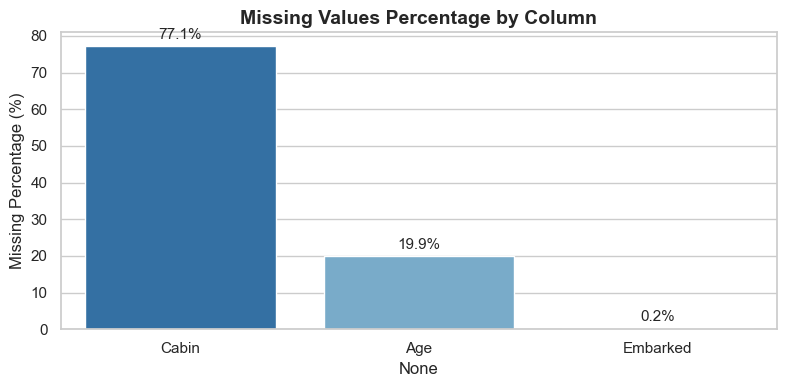

In [6]:
fig, ax = plt.subplots(figsize=(8, 4))
sns.barplot(x=missing_df.index, y=missing_df["Percentage (%)"], palette="Blues_r", ax=ax)
ax.set_title("Missing Values Percentage by Column", fontsize=14, fontweight="bold")
ax.set_ylabel("Missing Percentage (%)")
for p in ax.patches:
    ax.annotate(f"{p.get_height():.1f}%", (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='bottom', xytext=(0, 3), textcoords='offset points')
plt.tight_layout()
plt.show()


## 3. Target Variable Distribution: `Survived`

C:\Users\Sagar\AppData\Local\Temp\ipykernel_31400\3322013749.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x="Survived", palette=["#EF4444", "#10B981"], ax=axes[0])
C:\Users\Sagar\AppData\Local\Temp\ipykernel_31400\3322013749.py:6: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[0].set_xticklabels(["Did Not Survive (0)", "Survived (1)"])


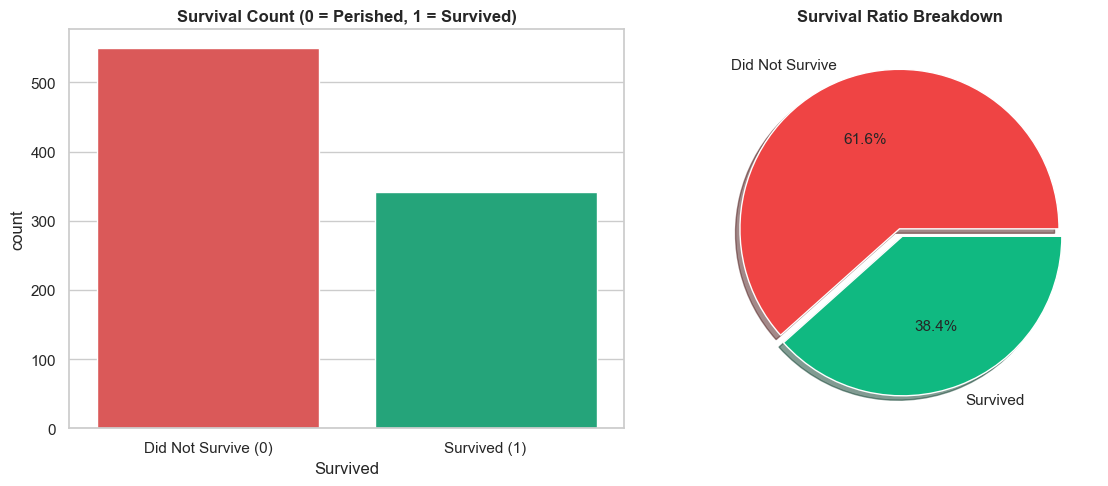

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Target count
sns.countplot(data=df, x="Survived", palette=["#EF4444", "#10B981"], ax=axes[0])
axes[0].set_title("Survival Count (0 = Perished, 1 = Survived)", fontweight="bold")
axes[0].set_xticklabels(["Did Not Survive (0)", "Survived (1)"])

# Target pie chart
df["Survived"].value_counts().plot.pie(
    autopct="%1.1f%%",
    colors=["#EF4444", "#10B981"],
    labels=["Did Not Survive", "Survived"],
    explode=[0, 0.05],
    shadow=True,
    ax=axes[1]
)
axes[1].set_ylabel("")
axes[1].set_title("Survival Ratio Breakdown", fontweight="bold")
plt.tight_layout()
plt.show()


## 4. Categorical Feature Relationships with Survival

Key demographic drivers:
- **Sex**: "Women and children first" maritime protocol.
- **Pclass**: Ticket class socioeconomic hierarchy.
- **Embarked**: Embarkation port.


C:\Users\Sagar\AppData\Local\Temp\ipykernel_31400\4026224956.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df, x="Sex", y="Survived", palette="Blues_r", ax=axes[0])
C:\Users\Sagar\AppData\Local\Temp\ipykernel_31400\4026224956.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df, x="Pclass", y="Survived", palette="Blues_r", ax=axes[1])
C:\Users\Sagar\AppData\Local\Temp\ipykernel_31400\4026224956.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df, x="Embarked", y="Survived", palette="Blues_r", ax=axes[2])


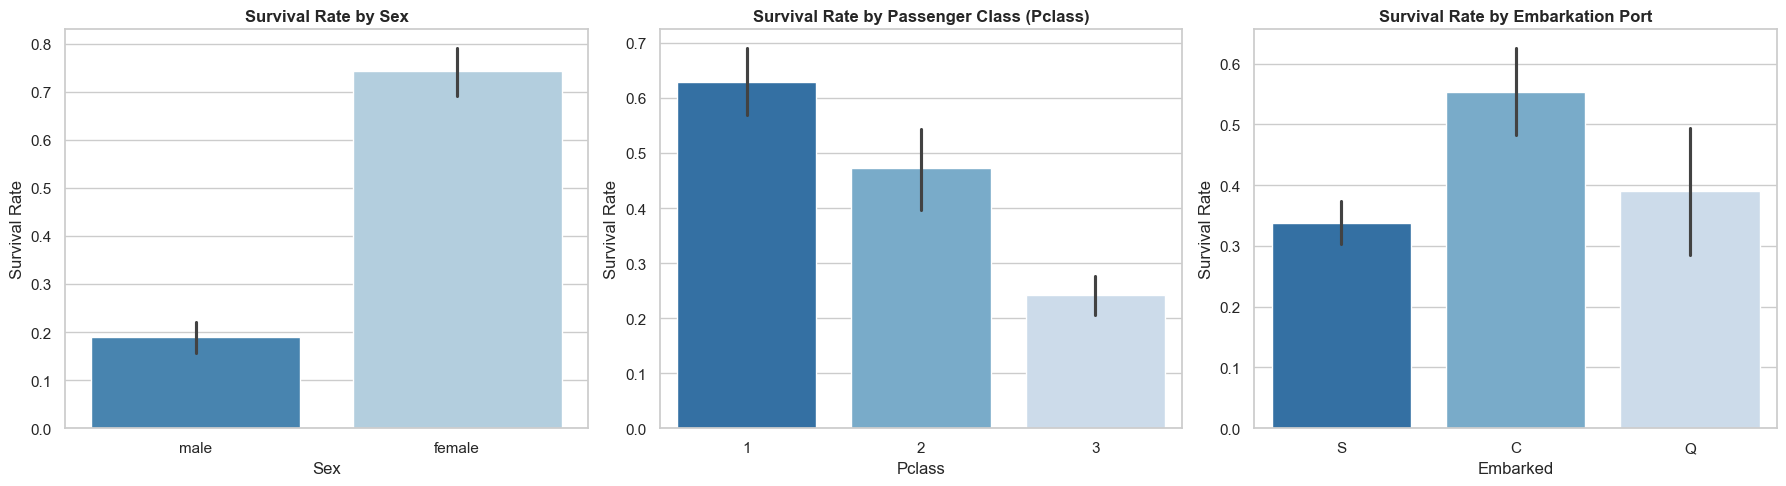

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sns.barplot(data=df, x="Sex", y="Survived", palette="Blues_r", ax=axes[0])
axes[0].set_title("Survival Rate by Sex", fontweight="bold")
axes[0].set_ylabel("Survival Rate")

sns.barplot(data=df, x="Pclass", y="Survived", palette="Blues_r", ax=axes[1])
axes[1].set_title("Survival Rate by Passenger Class (Pclass)", fontweight="bold")
axes[1].set_ylabel("Survival Rate")

sns.barplot(data=df, x="Embarked", y="Survived", palette="Blues_r", ax=axes[2])
axes[2].set_title("Survival Rate by Embarkation Port", fontweight="bold")
axes[2].set_ylabel("Survival Rate")

plt.tight_layout()
plt.show()


## 5. Age & Fare Continuous Distributions

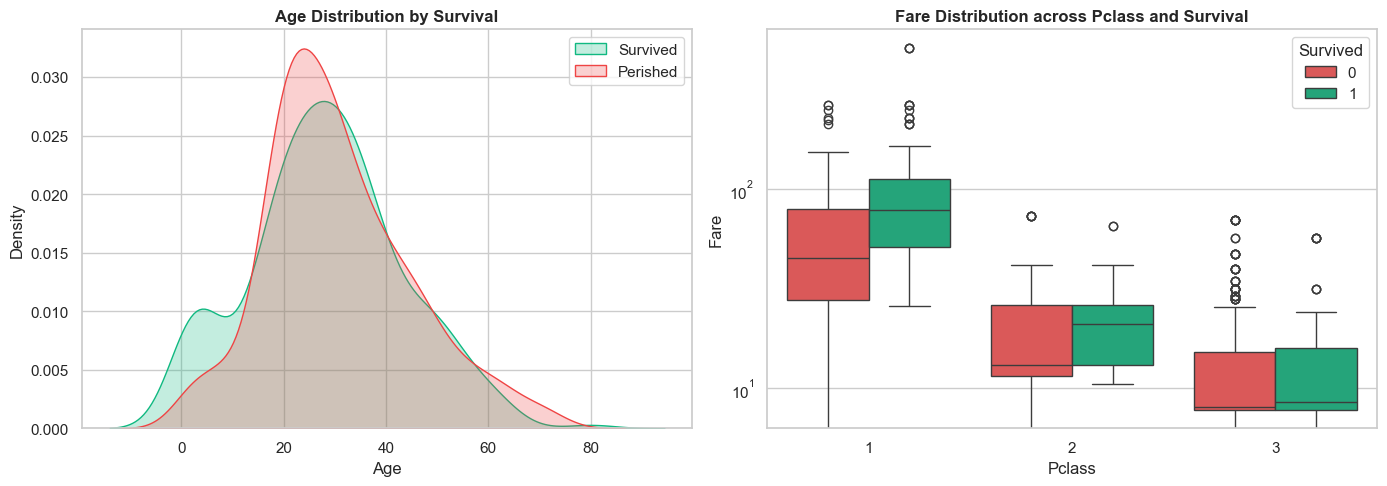

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Age distribution by survival
sns.kdeplot(data=df[df["Survived"] == 1]["Age"].dropna(), label="Survived", fill=True, color="#10B981", ax=axes[0])
sns.kdeplot(data=df[df["Survived"] == 0]["Age"].dropna(), label="Perished", fill=True, color="#EF4444", ax=axes[0])
axes[0].set_title("Age Distribution by Survival", fontweight="bold")
axes[0].legend()

# Fare distribution (log scale)
sns.boxplot(data=df, x="Pclass", y="Fare", hue="Survived", palette=["#EF4444", "#10B981"], ax=axes[1])
axes[1].set_title("Fare Distribution across Pclass and Survival", fontweight="bold")
axes[1].set_yscale("log")

plt.tight_layout()
plt.show()


## Key EDA Takeaways:
1. **Gender is the strongest baseline discriminator**: Females had a ~74% survival rate vs. ~19% for males.
2. **Passenger Class is crucial**: 1st Class passengers survived at >60%, whereas 3rd Class passengers survived at <25%.
3. **Age dynamics**: Young children (<10 years old) experienced higher survival rates.
4. **Data Preprocessing Needs**: Age has ~20% missing values requiring smart imputation; Embarked has 2 missing values; Cabin has >77% missing values.
